# Monolayer Ewald Energy Validation

**Goal.** Validate `ezwald`'s monolayer Ewald summation by reproducing, to high precision, the published static lattice energies of L. Bonsall and A. A. Maradudin, *"Some static and dynamical properties of a two-dimensional Wigner crystal,"* Phys. Rev. B **15**, 1959–1973 (1977), [doi:10.1103/PhysRevB.15.1959](https://doi.org/10.1103/PhysRevB.15.1959), for four two-dimensional Bravais lattices: square, primitive rectangular, centered rectangular, and hexagonal.

**What this tutorial covers:**
- Building a primitive cell and tiling it into a periodic supercell with `ezwald.geometry`
- Computing the per-particle Coulomb energy of a 2D lattice with `ezwald.ewald.Ewald.sum`
- Checking each result against an independent literature reference

**Requirements:** `ezwald`, `numpy`, `jax`, `matplotlib`. Runs in a few seconds on CPU.

## Background

For each lattice, `ezwald` places one electron per primitive cell, tiles the cell into an $n_x\times n_x$ supercell ($n_x=2$ throughout), and sums the Coulomb interaction with `ezwald.ewald.Ewald.sum`. Dividing by the number of particles gives the energy per particle.

Bonsall and Maradudin report each lattice's interaction energy as $E_I=-C/\sqrt{a_c}$, where $a_c$ is the area per particle and $C$ is a lattice-dependent constant given in their Eqs. (2.17)–(2.22). Because this counts each pair interaction twice, the ground-state energy per electron is $\frac{1}{2}E_I=-C/(2\sqrt{a_c})$ (their Eq. (2.13)), which is the quantity computed by `ezwald`. The reference values used below are exactly the paper's own $C$ constants — not fitted or adjusted in any way.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'  # this tutorial is fast enough that a CPU backend is sufficient
import jax
jax.config.update("jax_enable_x64", True)  # match the double precision used throughout ezwald

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from ezwald import ewald, geometry as geo

np.set_printoptions(precision=6, suppress=True)
print(f"jax {jax.__version__}, numpy {np.__version__}")

jax 0.5.0, numpy 2.2.2


## 1. Square lattice

Primitive cell: unit square lattice. Reference: Bonsall & Maradudin, Eq. (2.17), $C=3.900265$.

In [2]:
def energy_square(nx=2):
    # Primitive cell: square lattice
    axes_primitive = np.eye(2)

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.17)
    C = 3.900265
    ac = geo.calc_volume(axes_primitive)
    expected = -C / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle, C, ac

_ = energy_square()

ezwald = -1.950132   Bonsall & Maradudin = -1.950133   |difference| = 2.39e-08


## 2. Primitive rectangular lattice

Primitive cell: rectangular lattice, aspect ratio $\lambda=a_1/a_2=0.95$ (the value used by the paper as a worked example). Reference: Bonsall & Maradudin, Eq. (2.20), $C=3.898597$.

In [3]:
def energy_primitive_rectangle(nx=2):
    # Primitive cell: rectangular lattice (aspect ratio lambda < 1)
    lam = 0.95
    a2 = 1.0
    a1 = lam * a2
    axes_primitive = np.diag([a1, a2])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.20)
    C = 3.898597
    ac = geo.calc_volume(axes_primitive)
    expected = -C / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle, C, ac

_ = energy_primitive_rectangle()

ezwald = -1.999938   Bonsall & Maradudin = -1.999938   |difference| = 3.03e-07


## 3. Centered rectangular lattice

Primitive cell: centered rectangular lattice, aspect ratio $\lambda=0.95$. Reference: Bonsall & Maradudin, Eq. (2.22), $C=3.900647$.

In [4]:
def energy_centered_rectangle(nx=2):
    # Primitive cell: centered rectangular lattice (aspect ratio lambda < 1)
    lam = 0.95
    a2 = 1.0
    a1 = lam * a2
    axes_primitive = np.array([
        [a1,     0.0],
        [a1 / 2, a2 / 2]
    ])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.22)
    C = 3.900647
    ac = geo.calc_volume(axes_primitive)
    expected = -C / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle, C, ac

_ = energy_centered_rectangle()

ezwald = -2.829828   Bonsall & Maradudin = -2.829827   |difference| = 7.60e-07


## 4. Hexagonal lattice

Primitive cell: hexagonal (triangular) lattice. Reference: Bonsall & Maradudin, Eq. (2.18), $C=3.921034$ — the largest $C$ of the four lattices considered here, consistent with the paper's identification of the hexagonal lattice as the two-dimensional Wigner crystal ground state.

In [5]:
def energy_hexagonal(nx=2):
    # Primitive cell: hexagonal (triangular) lattice
    axes_primitive = np.array([
        [1.0, 0.0],
        [-0.5, np.sqrt(3) / 2]
    ])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.18)
    C = 3.921034
    ac = geo.calc_volume(axes_primitive)
    expected = -C / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle, C, ac

_ = energy_hexagonal()

ezwald = -2.106711   Bonsall & Maradudin = -2.106713   |difference| = 1.29e-06


## 5. Summary

The table below compares the energy per particle computed by `ezwald` against the result reported by Bonsall and Maradudin (1977) for each of the four lattices considered. Each lattice is evaluated at its own area per particle $a_c$, so the energies themselves are not on a common density scale: the centered rectangular lattice, whose primitive cell has the smallest area, has the most negative energy. The lattices are ranked by the density-independent constant $C$, which is largest for the hexagonal lattice, the two-dimensional Wigner crystal ground state.

ezwald = -1.950132   Bonsall & Maradudin = -1.950133   |difference| = 2.39e-08
ezwald = -1.999938   Bonsall & Maradudin = -1.999938   |difference| = 3.03e-07
ezwald = -2.829828   Bonsall & Maradudin = -2.829827   |difference| = 7.60e-07
ezwald = -2.106711   Bonsall & Maradudin = -2.106713   |difference| = 1.29e-06


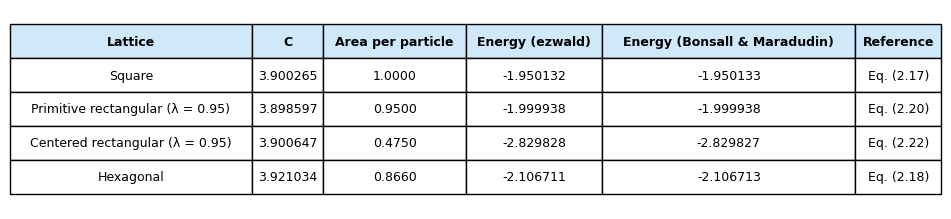

In [6]:
lattices = [
    ("Square", energy_square, "Eq. (2.17)"),
    ("Primitive rectangular (λ = 0.95)", energy_primitive_rectangle, "Eq. (2.20)"),
    ("Centered rectangular (λ = 0.95)", energy_centered_rectangle, "Eq. (2.22)"),
    ("Hexagonal", energy_hexagonal, "Eq. (2.18)"),
]

col_labels = ["Lattice", "C", "Area per particle", "Energy (ezwald)", "Energy (Bonsall & Maradudin)", "Reference"]
cell_text = []
for name, energy_fn, eq in lattices:
    E, C, ac = energy_fn()
    cell_text.append([name, f"{C:.6f}", f"{ac:.4f}", f"{float(E):.6f}", f"{-C / (2 * ac ** 0.5):.6f}", eq])

fig, ax = plt.subplots(figsize=(10.5, 0.5 + 0.45 * len(cell_text)))
ax.axis("off")

mpl_table = ax.table(cellText=cell_text, colLabels=col_labels, cellLoc="center", loc="center")
mpl_table.auto_set_font_size(False)
mpl_table.set_fontsize(9)
mpl_table.auto_set_column_width(col=list(range(len(col_labels))))
mpl_table.scale(1, 1.8)

for (row, col), cell in mpl_table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#cfe8fa")

fig.tight_layout()

## Conclusion

All four lattices agree with Bonsall and Maradudin's published energies to within $2\times10^{-6}$, confirming that `ezwald`'s monolayer Ewald summation reproduces the known static Coulomb energy of a two-dimensional Wigner crystal. Increasing the Ewald cutoffs changes the `ezwald` energies by less than $3\times10^{-7}$, so the remaining differences, largest for the hexagonal lattice, come from the last printed digits of the published constants rather than from the summation.